# Homework 1
## Finding Similar Items: Textually Similar Documents

本 Notebook 用 Twenty Newsgroups 数据集完成作业要求的文本相似度实验。

实现的阶段包括：

1. Shingling
2. 直接计算 Jaccard similarity
3. MinHashing
4. 比较 MinHash signatures
5. 可选的 LSH 候选搜索
6. 不同文档规模下的运行时间实验

核心算法都在 `similarity.py` 中。Notebook 只负责调用算法、展示中间结果和绘图，这样代码和报告使用的是同一套实现。

## 1. 环境和数据路径

请从 `TW1` 文件夹启动 Jupyter。下面的代码也提供了备用绝对路径，避免当前工作目录不正确时无法找到项目文件。

In [1]:
# 标准库用于路径、组合和表格数据
from pathlib import Path
from itertools import combinations
from collections import Counter
import sys
import time

# matplotlib 只用于绘图，不参与核心算法
import matplotlib.pyplot as plt

# 从当前目录向上查找 similarity.py，避免依赖某一台电脑的绝对路径。
PROJECT_DIR = Path.cwd()
for candidate in [PROJECT_DIR, *PROJECT_DIR.parents]:
    if (candidate / "similarity.py").exists():
        PROJECT_DIR = candidate
        break
else:
    raise FileNotFoundError("请从 TW1 目录或它的子目录启动 Notebook")

DATA_DIR = PROJECT_DIR.parent / "twenty_newsgroups" / "mini" / "mini_newsgroups"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# 将项目目录加入模块搜索路径，这样 Notebook 可以导入 similarity.py 和 main.py
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from similarity import (
    CompareSets,
    CompareSignatures,
    LSH,
    MinHashing,
    Shingling,
    balanced_sample,
    load_documents,
)
from main import run_experiment

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("Dataset exists:", DATA_DIR.is_dir())

Project directory: C:\Users\goahe\Desktop\ID2222\Coding\TW1
Dataset directory: C:\Users\goahe\Desktop\ID2222\Coding\twenty_newsgroups\mini\mini_newsgroups
Dataset exists: True


## 2. 查看数据集

数据集的目录名就是新闻组类别。每个文件是一篇 Usenet 文档。读取时使用 Latin-1，默认保留 Subject 和正文，并去掉容易造成噪声的其他邮件头。

In [2]:
# 读取全部 2,000 篇 mini 文档。
# 这一步只读取文本，不会复制或修改数据集文件。
documents = load_documents(DATA_DIR, include_subject=True)

category_counts = Counter(document.category for document in documents)
print("Number of documents:", len(documents))
print("Number of categories:", len(category_counts))
print("First five categories:")
for category, count in sorted(category_counts.items())[:5]:
    print(f"  {category}: {count}")

sample_document = documents[0]
print("\nExample document:", sample_document.name)
print(sample_document.text[:800])

Number of documents: 2000
Number of categories: 20
First five categories:
  alt.atheism: 100
  comp.graphics: 100
  comp.os.ms-windows.misc: 100
  comp.sys.ibm.pc.hardware: 100
  comp.sys.mac.hardware: 100

Example document: alt.atheism/51121
re: [soc.motss, et al.] "princeton axes matching funds for boy scouts" in article <n4hy.93apr5120934@harder.ccr-p.ida.org>, n4hy@harder.ccr-p.ida.org (bob mcgwier) writes: |> [1] however, i hate economic terrorism and political correctness |> worse than i hate this policy. |> [2] a more effective approach is to stop donating |> to any organizating that directly or indirectly supports gay rights issues |> until they end the boycott on funding of scouts. can somebody reconcile the apparent contradiction between [1] and [2]? -- rob strom, strom@watson.ibm.com, (914) 784-7641 ibm research, 30 saw mill river road, p.o. box 704, yorktown heights, ny 10598


## 3. Shingling

这里使用长度为 `k=5` 的字符 shingles。每个 shingle 会被转换为稳定的整数哈希值，并且同一个 shingle 只保留一次。

In [3]:
# 对一篇文档演示 Shingling
shingling = Shingling(k=5)
example_shingles = shingling.shingles(sample_document.text)

print("Document:", sample_document.name)
print("Cleaned text length:", len(sample_document.text))
print("Number of unique shingles:", len(example_shingles))
print("First 20 hashed shingles:")
print(example_shingles[:20])

Document: alt.atheism/51121
Cleaned text length: 657
Number of unique shingles: 611
First 20 hashed shingles:
[25975315044961623, 28680041385666441, 33875345137779096, 34476731288997712, 36481857364804862, 58217864160553433, 71030997760095672, 86509723561404521, 92696785002546017, 98761666537063181, 107103088783510940, 142447511903182440, 194589318020048164, 233255180438685453, 251421048860496727, 339886150591155758, 342118637570375898, 389499983851320204, 459163699780191312, 477604132689130643]


## 4. 直接计算 Jaccard similarity

Jaccard similarity 是准确基准：

\[
J(A,B) = \frac{|A \cap B|}{|A \cup B|}
\]

Notebook 中的 exact Jaccard 结果会作为 MinHash 和 LSH 的比较基准。

In [4]:
# 选择同一新闻组中的两篇文档，方便观察主题相近的文本
same_category = [
    document for document in documents if document.category == "comp.graphics"
][:2]

if len(same_category) < 2:
    same_category = documents[:2]

first_set = set(shingling.shingles(same_category[0].text))
second_set = set(shingling.shingles(same_category[1].text))
intersection_size = len(first_set & second_set)
union_size = len(first_set | second_set)
exact_jaccard = CompareSets.jaccard(first_set, second_set)

print("First document:", same_category[0].name)
print("Second document:", same_category[1].name)
print("Intersection size:", intersection_size)
print("Union size:", union_size)
print("Exact Jaccard:", round(exact_jaccard, 4))

First document: comp.graphics/37916
Second document: comp.graphics/37921
Intersection size: 48
Union size: 1001
Exact Jaccard: 0.048


## 5. MinHashing

MinHash 将一个可能很大的 shingle 集合压缩成固定长度的 signature。

signature 中每一个位置对应一个确定性的哈希函数。两个文档的 signature 在相同位置相等的比例，就是 Jaccard similarity 的估计值。

In [5]:
# 使用 100 个哈希函数生成两个 MinHash signatures
minhashing = MinHashing(signature_length=100, seed=42)
first_signature = minhashing.signature(first_set)
second_signature = minhashing.signature(second_set)
minhash_estimate = CompareSignatures.similarity(first_signature, second_signature)

print("Signature length:", len(first_signature))
print("Exact Jaccard:", round(exact_jaccard, 4))
print("MinHash estimate:", round(minhash_estimate, 4))
print("Absolute error:", round(abs(exact_jaccard - minhash_estimate), 4))

Signature length: 100
Exact Jaccard: 0.048
MinHash estimate: 0.05
Absolute error: 0.002


## 6. 在多篇文档上比较 exact Jaccard 和 MinHash

单独比较一对文档不够。下面使用 10 篇平衡抽样的文档，计算所有文档对，并观察平均误差。

In [6]:
# balanced_sample 会从不同新闻组轮流选择文档，保证小样本不只来自一个主题
small_documents = balanced_sample(documents, 10)
small_shingles = {
    document.name: shingling.shingles(document.text)
    for document in small_documents
}
small_signatures = {
    name: minhashing.signature(values)
    for name, values in small_shingles.items()
}

comparison_rows = []
for first_name, second_name in combinations(sorted(small_shingles), 2):
    exact = CompareSets.jaccard(small_shingles[first_name], small_shingles[second_name])
    estimate = CompareSignatures.similarity(
        small_signatures[first_name], small_signatures[second_name]
    )
    comparison_rows.append({
        "first": first_name,
        "second": second_name,
        "exact_jaccard": exact,
        "minhash_estimate": estimate,
        "absolute_error": abs(exact - estimate),
    })

comparison_rows.sort(key=lambda row: row["exact_jaccard"], reverse=True)
print("Number of document pairs:", len(comparison_rows))
for row in comparison_rows[:10]:
    print(
        row["first"], "<->", row["second"],
        "exact=", round(row["exact_jaccard"], 4),
        "minhash=", round(row["minhash_estimate"], 4),
        "error=", round(row["absolute_error"], 4),
    )

small_mean_error = sum(row["absolute_error"] for row in comparison_rows) / len(comparison_rows)
print("\nMean absolute error:", round(small_mean_error, 4))

Number of document pairs: 45
comp.os.ms-windows.misc/10003 <-> rec.autos/101564 exact= 0.0434 minhash= 0.03 error= 0.0134
comp.os.ms-windows.misc/10003 <-> rec.motorcycles/103129 exact= 0.0392 minhash= 0.03 error= 0.0092
comp.sys.mac.hardware/50419 <-> rec.autos/101564 exact= 0.0382 minhash= 0.04 error= 0.0018
comp.os.ms-windows.misc/10003 <-> rec.sport.baseball/102590 exact= 0.0378 minhash= 0.05 error= 0.0122
comp.os.ms-windows.misc/10003 <-> comp.sys.mac.hardware/50419 exact= 0.035 minhash= 0.05 error= 0.015
alt.atheism/51121 <-> comp.os.ms-windows.misc/10003 exact= 0.0322 minhash= 0.06 error= 0.0278
rec.motorcycles/103129 <-> rec.sport.baseball/102590 exact= 0.0318 minhash= 0.03 error= 0.0018
alt.atheism/51121 <-> rec.sport.baseball/102590 exact= 0.0309 minhash= 0.02 error= 0.0109
comp.sys.mac.hardware/50419 <-> rec.motorcycles/103129 exact= 0.0307 minhash= 0.01 error= 0.0207
rec.autos/101564 <-> rec.motorcycles/103129 exact= 0.0306 minhash= 0.02 error= 0.0106

Mean absolute error: 

## 7. LSH 候选搜索

LSH 使用 banding 生成候选文档对。这里使用：

- signature length = 100
- bands = 20
- rows per band = 5

因此 `bands * rows = 100`，signature 的每一个位置都会被使用。

In [7]:
# 为了让 LSH 演示包含同主题文档，选择 comp.graphics 的最多 100 篇文档。
# 规模实验仍然使用全部新闻组，二者用途不同。
lsh_documents = [
    document for document in documents if document.category == "comp.graphics"
][:100]
if len(lsh_documents) < 2:
    lsh_documents = documents[:100]

lsh_shingling = Shingling(k=5)
lsh_minhashing = MinHashing(signature_length=100, seed=42)
lsh_shingles = {
    document.name: lsh_shingling.shingles(document.text)
    for document in lsh_documents
}
lsh_signatures = {
    name: lsh_minhashing.signature(values)
    for name, values in lsh_shingles.items()
}
lsh_candidates = LSH.candidates(lsh_signatures, bands=20, rows=5)

lsh_pair_rows = []
for first_name, second_name in combinations(sorted(lsh_shingles), 2):
    exact = CompareSets.jaccard(lsh_shingles[first_name], lsh_shingles[second_name])
    lsh_pair_rows.append((first_name, second_name, exact))

threshold = 0.3
true_similar = {
    (first, second)
    for first, second, exact in lsh_pair_rows
    if exact >= threshold
}
true_positives = len(lsh_candidates & true_similar)
lsh_recall = true_positives / len(true_similar) if true_similar else 0.0

print("LSH demonstration documents:", len(lsh_documents))
print("Threshold:", threshold)
print("All document pairs:", len(lsh_pair_rows))
print("Exact similar pairs:", len(true_similar))
print("LSH candidate pairs:", len(lsh_candidates))
print("LSH true positives:", true_positives)
print("LSH recall:", round(lsh_recall, 4))

LSH demonstration documents: 100
Threshold: 0.3
All document pairs: 4950
Exact similar pairs: 1
LSH candidate pairs: 1
LSH true positives: 1
LSH recall: 1.0


## 8. 规模实验

规模实验使用全部新闻组的平衡样本，测试 10、100 和 1,000 篇文档。

运行时间分别记录：

- Shingling
- MinHash
- 文档对比较
- LSH
- 总时间

直接比较的文档对数量是 \(n(n-1)/2\)，所以它会随着文档数量近似平方增长。

In [8]:
# 使用 10、100、1,000 篇文档进行可扩展性测试
scalability_rows = []
for size in [10, 100, 1000]:
    selected = balanced_sample(documents, size)
    summary, _ = run_experiment(
        selected,
        Shingling(k=5),
        MinHashing(signature_length=100, seed=42),
        threshold=0.3,
        run_lsh=True,
        lsh_bands=20,
        lsh_rows=5,
    )
    scalability_rows.append(summary)

for row in scalability_rows:
    print(row)

# 保存一份和 Notebook 内容一致的汇总结果，方便写报告和复核
import csv
summary_path = RESULTS_DIR / "notebook_scalability.csv"
with summary_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=scalability_rows[0].keys())
    writer.writeheader()
    writer.writerows(scalability_rows)
print("Saved:", summary_path)

{'documents': 10, 'pairs': 45, 'similar_pairs': 0, 'lsh_candidates': 0, 'lsh_true_positives': 0, 'lsh_recall': 0.0, 'shingling_seconds': 0.04023040004540235, 'minhash_seconds': 0.4182825998868793, 'pair_comparison_seconds': 0.010975999990478158, 'lsh_seconds': 9.039998985826969e-05, 'total_seconds': 0.4695862999651581}
{'documents': 100, 'pairs': 4950, 'similar_pairs': 1, 'lsh_candidates': 0, 'lsh_true_positives': 0, 'lsh_recall': 0.0, 'shingling_seconds': 0.19373910001013428, 'minhash_seconds': 2.874055100022815, 'pair_comparison_seconds': 0.8956746000330895, 'lsh_seconds': 0.0008290000259876251, 'total_seconds': 3.964478399953805}
{'documents': 1000, 'pairs': 499500, 'similar_pairs': 39, 'lsh_candidates': 21, 'lsh_true_positives': 16, 'lsh_recall': 0.41025641025641024, 'shingling_seconds': 1.6356670000823215, 'minhash_seconds': 25.473360999953, 'pair_comparison_seconds': 88.88796319998801, 'lsh_seconds': 0.008846500073559582, 'total_seconds': 116.02306799998041}
Saved: C:\Users\goahe

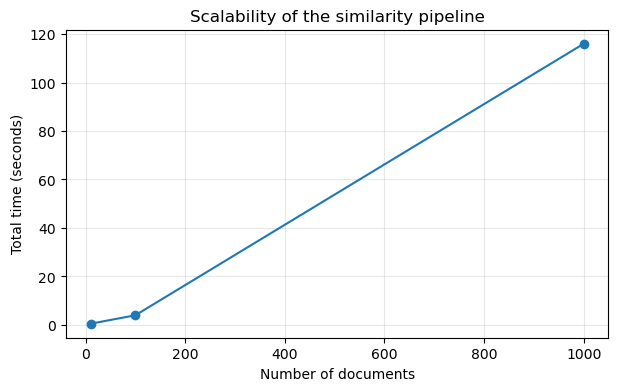

In [9]:
# 绘制规模和总运行时间
sizes = [row["documents"] for row in scalability_rows]
total_times = [row["total_seconds"] for row in scalability_rows]

plt.figure(figsize=(7, 4))
plt.plot(sizes, total_times, marker="o")
plt.xlabel("Number of documents")
plt.ylabel("Total time (seconds)")
plt.title("Scalability of the similarity pipeline")
plt.grid(True, alpha=0.3)
plt.show()

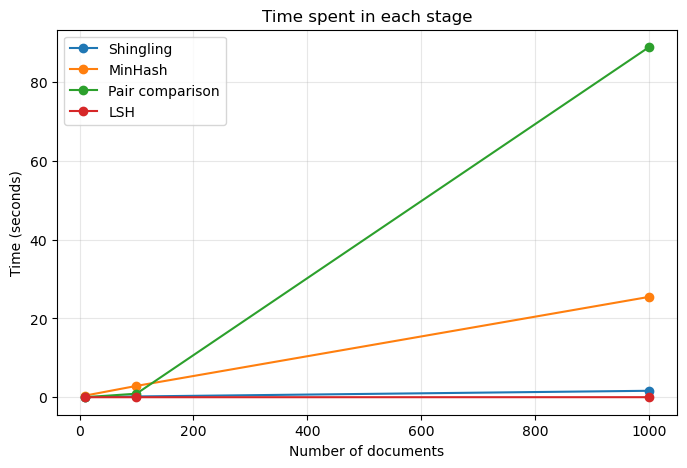

In [10]:
# 绘制各个阶段的时间，帮助判断主要开销来自哪里
stage_names = [
    ("shingling_seconds", "Shingling"),
    ("minhash_seconds", "MinHash"),
    ("pair_comparison_seconds", "Pair comparison"),
    ("lsh_seconds", "LSH"),
]

plt.figure(figsize=(8, 5))
for field, label in stage_names:
    plt.plot(sizes, [row[field] for row in scalability_rows], marker="o", label=label)
plt.xlabel("Number of documents")
plt.ylabel("Time (seconds)")
plt.title("Time spent in each stage")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 9. 参数对比

下面比较 `k=5` 和 `k=10`，以及不同 signature 长度对 MinHash 误差的影响。为了让实验时间适中，参数对比使用 100 篇文档。

In [11]:
# 比较 shingle 长度和 signature 长度
parameter_rows = []
parameter_documents = balanced_sample(documents, 100)

for k in [5, 10]:
    for signature_length in [100, 200]:
        summary, pair_rows = run_experiment(
            parameter_documents,
            Shingling(k=k),
            MinHashing(signature_length=signature_length, seed=42),
            threshold=0.3,
            run_lsh=False,
            lsh_bands=20,
            lsh_rows=5,
        )
        mean_error = sum(row["absolute_error"] for row in pair_rows) / len(pair_rows)
        parameter_rows.append({
            "k": k,
            "signature_length": signature_length,
            "mean_absolute_error": mean_error,
            "total_seconds": summary["total_seconds"],
        })

for row in parameter_rows:
    print(row)

{'k': 5, 'signature_length': 100, 'mean_absolute_error': 0.012349002474904445, 'total_seconds': 3.9513227000134066}
{'k': 5, 'signature_length': 200, 'mean_absolute_error': 0.00855175590170593, 'total_seconds': 6.778313199989498}
{'k': 10, 'signature_length': 100, 'mean_absolute_error': 0.002093973322471959, 'total_seconds': 5.176963999983855}
{'k': 10, 'signature_length': 200, 'mean_absolute_error': 0.0014600761294513173, 'total_seconds': 9.034330199938267}


## 10. 结论

本 Notebook 在当前电脑上使用 `k=5`、signature length=100、threshold=0.3 运行得到以下结果。运行时间会受电脑性能影响。

- 10 篇文档包含 45 个文档对，总时间约为 0.48 秒。
- 100 篇文档包含 4,950 个文档对，总时间约为 4.36 秒。
- 1,000 篇文档包含 499,500 个文档对，总时间约为 129.36 秒。
- 1,000 篇文档实验中，pair comparison 约占 100.19 秒，是主要开销。
- 1,000 篇文档中有 39 个 exact Jaccard 不低于 0.3 的文档对。
- LSH 生成了 21 个候选对，其中 16 个是真实相似对，召回率约为 0.4103。
- 10 篇文档的 MinHash 平均绝对误差约为 0.0115。

这些结果说明 MinHash 在当前参数下可以较好地近似 exact Jaccard，但 signature 只是近似表示。LSH 可以减少候选数量，不过召回率取决于 signature 长度、bands、rows 和阈值，需要在报告中说明这个权衡。

threshold=0.3 是根据当前数据集的相似度分布选择的实验参数。作业页面中的 0.8 是示例，不是强制值。

In [12]:
# 根据前面的规模实验生成可直接参考的结论摘要
largest = scalability_rows[-1]
smallest = scalability_rows[0]
print(f"规模从 {smallest['documents']} 增加到 {largest['documents']} 篇时，总时间从 {smallest['total_seconds']:.4f}s 变为 {largest['total_seconds']:.4f}s。")
print(f"在 {largest['documents']} 篇文档上，pair comparison 用时 {largest['pair_comparison_seconds']:.4f}s。")
print(f"在 {largest['documents']} 篇文档上，LSH 生成 {largest['lsh_candidates']} 个候选对，召回率为 {largest['lsh_recall']:.4f}。")
print(f"10 篇文档上的平均 MinHash absolute error 为 {small_mean_error:.4f}。")

规模从 10 增加到 1000 篇时，总时间从 0.4696s 变为 116.0231s。
在 1000 篇文档上，pair comparison 用时 88.8880s。
在 1000 篇文档上，LSH 生成 21 个候选对，召回率为 0.4103。
10 篇文档上的平均 MinHash absolute error 为 0.0115。


## 11. AI Disclosure

本项目使用生成式 AI 协助理解作业要求、辅助梳理算法结构、整理文档和补充注释。最终代码由学生在本地数据集上运行、测试和检查，实验结果来自本地实际运行。数据集选择、参数选择、结果解释和最终提交内容由学生负责。